Jeriel Fonseca Ramirez

Librerias y carga 

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

sns.set_style("whitegrid")

# Carpeta donde está el set de datos
carpeta = Path(r"C:\Users\jerie\Downloads\Set_de_datos_Proyecto_Minería_I_Grupo_I")
print("¿Existe?", carpeta.exists())
print("¿Es una carpeta?", carpeta.is_dir())

# Mostrar los archivos CSV que hay dentro (también en subcarpetas)
for archivo in carpeta.rglob("*.csv"):
    print(archivo)

¿Existe? True
¿Es una carpeta? True
C:\Users\jerie\Downloads\Set_de_datos_Proyecto_Minería_I_Grupo_I\ai_agent_incidents.csv
C:\Users\jerie\Downloads\Set_de_datos_Proyecto_Minería_I_Grupo_I\Employee_Performance_Imputed_Distribution.csv


In [13]:
ruta = carpeta / "ai_agent_incidents.csv"   # si el nombre o la subcarpeta son distintos, cámbialo aquí
df = pd.read_csv(ruta)

print("Registros:", df.shape[0], "| Variables:", df.shape[1])
df.head()

Registros: 395 | Variables: 17


,incident_id,date,year,month,title,attack_type_code,attack_type_name,incident_kind,severity,confidence_level,real_harm_confirmed,ai_involvement,region,is_landmark_event,summary,source_count,primary_source_url
0,2024-12-01-storm-azure-llmjacking,2024-12-01,2024,2024-12,Storm-2139 Azure OpenAI LLMjacking,CRED,Credential & Secret Theft,incident,high,a,True,confirmed,GLOBAL,False,Microsoft's DCU filed suit in the Eastern Dist...,1,https://blogs.microsoft.com/on-the-issues/2025...
1,2025-01-01-maine-town-deepfake-phishing,2025-01-01,2025,2025-01,AI phishing and deepfake voice hit a small Mai...,OTHER,Unclassified AI Incident,incident,medium,a,True,confirmed,US,False,Impersonating town officials to approve tens o...,1,https://genai.owasp.org/2025/03/06/owasp-gen-a...
2,2025-01-20-hk-voice-clone-usdt-fraud,2025-01-20,2025,2025-01,Hong Kong AI voice-clone crypto fraud,OTHER,Unclassified AI Incident,incident,medium,a,True,confirmed,HK,False,Cloned a finance manager's voice; 3 USDT trans...,1,https://genai.owasp.org/2025/03/06/owasp-gen-a...
3,2025-01-23-operator-fa-bu-bei-jing,2025-01-23,2025,2025-01,OpenAI Operator launches (context entry),GOV,AI Governance & Policy Failure,policy,info,a,False,confirmed,GLOBAL,False,The first consumer-facing computer-use agent; ...,1,https://openai.com/index/operator-system-card/
4,2025-01-26-harbin-asian-winter-games-attack,2025-01-26,2025,2025-01,Harbin Asian Winter Games systems attacked,WEAPON,AI Weaponization & Malicious Tooling,incident,high,d,True,disputed,CN,False,National Computer Virus Emergency Response Cen...,1,http://www.news.cn/sports/20250404/9b6d2457ca4...


Observamos el dataset

In [14]:
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   incident_id          395 non-null    object
 1   date                 395 non-null    object
 2   year                 395 non-null    int64 
 3   month                395 non-null    object
 4   title                395 non-null    object
 5   attack_type_code     395 non-null    object
 6   attack_type_name     395 non-null    object
 7   incident_kind        395 non-null    object
 8   severity             395 non-null    object
 9   confidence_level     395 non-null    object
 10  real_harm_confirmed  395 non-null    bool  
 11  ai_involvement       395 non-null    object
 12  region               395 non-null    object
 13  is_landmark_event    395 non-null    bool  
 14  summary              395 non-null    object
 15  source_count         395 non-null    int64 
 16  primary_

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
incident_id,395,395,2024-12-01-storm-azure-llmjacking,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,395,241,2026-09-16,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,395.0,NaN,NaN,NaN,2025.688608,0.469092,2024.0,2025.0,2026.0,2026.0,2026.0
month,395,23,2026-09,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,395,395,Storm-2139 Azure OpenAI LLMjacking,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
attack_type_code,395,55,GOV,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN
attack_type_name,395,55,AI Governance & Policy Failure,62,NaN,NaN,NaN,NaN,NaN,NaN,NaN
incident_kind,395,5,incident,162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
severity,395,5,high,157,NaN,NaN,NaN,NaN,NaN,NaN,NaN
confidence_level,395,4,a,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Diccionario

In [15]:
diccionario = pd.DataFrame([
    ("incident_id",         "Identificador",            "Texto",              "Identificador único del registro",                          "Se descarta (identificador)"),
    ("date",                "Fecha",                    "Fecha",              "Fecha del evento",                                          "Se usa para ver la evolución en el tiempo"),
    ("year",                "Año",                      "Numérica",           "Año del evento (2024-2026)",                                "Se agrupa: 2026 / 2025 o antes"),
    ("month",               "Mes",                      "Texto",              "Mes del evento",                                            "Se descarta (sale de date)"),
    ("title",               "Título",                   "Texto",              "Título del registro",                                       "Se descarta (texto libre)"),
    ("attack_type_code",    "Código de tipo de ataque", "Categórica",         "Código del tipo de ataque",                                 "Se descarta (repite attack_type_name)"),
    ("attack_type_name",    "Tipo de ataque",           "Categórica nominal", "Tipo de ataque (55 categorías)",                            "Se agrupa en 7 y se codifica"),
    ("incident_kind",       "Tipo de registro",         "Categórica nominal", "Clase: incidente, investigación, política, vulnerabilidad, reporte", "Se codifica"),
    ("severity",            "Gravedad",                 "Categórica ordinal", "Gravedad: informativa, baja, media, alta, crítica",         "Se codifica"),
    ("confidence_level",    "Nivel de confianza",       "Categórica ordinal", "Confianza de la fuente: A (alta) a D (baja)",               "Se agrupa (A, B, C o D) y se codifica"),
    ("real_harm_confirmed", "Daño real confirmado",     "Booleana",           "Si se confirmó daño real",                                  "Se codifica (Sí/No)"),
    ("ai_involvement",      "Participación de la IA",   "Categórica nominal", "Participación de la IA (confirmada, disputada...)",         "Se agrupa (Confirmada/Otra) y se codifica"),
    ("region",              "Región",                   "Categórica nominal", "Región (algunas traen varias separadas por ;)",             "Se simplifica y se codifica"),
    ("is_landmark_event",   "Evento emblemático",       "Booleana",           "Si es un evento emblemático/histórico",                     "Se codifica (Sí/No)"),
    ("summary",             "Resumen",                  "Texto",              "Resumen del evento",                                        "Se descarta (texto libre)"),
    ("source_count",        "Número de fuentes",        "Numérica",           "Número de fuentes (siempre 1)",                             "Se descarta (constante)"),
    ("primary_source_url",  "Enlace de la fuente",      "Texto",              "Enlace de la fuente",                                       "Se descarta (identificador)"),
], columns=["Variable (CSV)", "Nombre en español", "Tipo", "Descripción", "Uso en el análisis"])
diccionario

,Variable (CSV),Nombre en español,Tipo,Descripción,Uso en el análisis
0,incident_id,Identificador,Texto,Identificador único del registro,Se descarta (identificador)
1,date,Fecha,Fecha,Fecha del evento,Se usa para ver la evolución en el tiempo
2,year,Año,Numérica,Año del evento (2024-2026),Se agrupa: 2026 / 2025 o antes
3,month,Mes,Texto,Mes del evento,Se descarta (sale de date)
4,title,Título,Texto,Título del registro,Se descarta (texto libre)
5,attack_type_code,Código de tipo de ataque,Categórica,Código del tipo de ataque,Se descarta (repite attack_type_name)
6,attack_type_name,Tipo de ataque,Categórica nominal,Tipo de ataque (55 categorías),Se agrupa en 7 y se codifica
7,incident_kind,Tipo de registro,Categórica nominal,"Clase: incidente, investigación, política, vul...",Se codifica
8,severity,Gravedad,Categórica ordinal,"Gravedad: informativa, baja, media, alta, crítica",Se codifica
9,confidence_level,Nivel de confianza,Categórica ordinal,Confianza de la fuente: A (alta) a D (baja),"Se agrupa (A, B, C o D) y se codifica"


Posible objetivo: Objetivo: descubrir qué tipos de registros existen sobre incidentes con agentes de IA
y agruparlos según su gravedad, daño real, tipo de ataque y región, para saber
cuáles son los más críticos.

Preguntas:
1. ¿Cómo se distribuyen la gravedad, el tipo de registro y el tipo de ataque?
2. ¿La gravedad se relaciona con el daño real?
3. ¿Cómo cambió el número de registros en el tiempo?
4. ¿Existen grupos naturales (clusters) de registros parecidos?

Limpieza

In [16]:
print("Nulos:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())
print("Valores de source_count:", df["source_count"].unique())

df["date"] = pd.to_datetime(df["date"])
df["region_principal"] = df["region"].str.split(";").str[0]
df = df.drop(columns=["incident_id", "title", "summary", "primary_source_url",
                      "source_count", "attack_type_code", "month", "region"])
df.shape

Nulos: 0
Filas duplicadas: 0
Valores de source_count: [1]


(395, 10)

Traducimos a español las variables

In [17]:
# 1) Nombres de columnas en español
df = df.rename(columns={"date": "fecha", "year": "anio", "attack_type_name": "tipo_ataque",
                        "incident_kind": "tipo_registro", "severity": "gravedad",
                        "confidence_level": "confianza", "real_harm_confirmed": "dano_real",
                        "ai_involvement": "participacion_ia", "is_landmark_event": "evento_emblematico",
                        "region_principal": "region"})

# 2) Valores en español
df["gravedad"] = df["gravedad"].map({"info": "Informativa", "low": "Baja", "medium": "Media",
                                     "high": "Alta", "critical": "Crítica"})
df["tipo_registro"] = df["tipo_registro"].map({"incident": "Incidente", "research": "Investigación",
                                               "policy": "Política", "vulnerability": "Vulnerabilidad",
                                               "report": "Reporte"})
df["confianza"] = df["confianza"].str.upper()
df["participacion_ia"] = df["participacion_ia"].map({"confirmed": "Confirmada", "disputed": "Disputada",
                                                     "unverified": "No verificada", "not-applicable": "No aplica"})
df["dano_real"] = df["dano_real"].map({True: "Sí", False: "No"})
df["evento_emblematico"] = df["evento_emblematico"].map({True: "Sí", False: "No"})
df["region"] = df["region"].replace({"GLOBAL": "Global", "US": "EE. UU.", "CN": "China", "EU": "Unión Europea",
                                     "LATAM": "Latinoamérica", "KR": "Corea del Sur", "AU": "Australia",
                                     "JP": "Japón", "UK": "Reino Unido", "TW": "Taiwán", "HK": "Hong Kong",
                                     "SEA": "Sudeste Asiático"})
df["tipo_ataque"] = df["tipo_ataque"].replace({
    "AI Governance & Policy Failure": "Falla de gobernanza y políticas de IA",
    "AI Weaponization & Malicious Tooling": "IA como arma y herramientas maliciosas",
    "AI Infrastructure & Cluster Compromise": "Compromiso de infraestructura de IA",
    "Unclassified AI Incident": "Incidente de IA sin clasificar",
    "IPI;EXFIL": "Inyección indirecta + exfiltración (IPI;EXFIL)",
    "Credential & Secret Theft": "Robo de credenciales y secretos",
    "Autonomous Rogue Agent Behavior": "Comportamiento descontrolado del agente",
    "Benchmark & Evaluation Poisoning": "Envenenamiento de evaluaciones",
    "SUPPLY;CRED": "Cadena de suministro + credenciales (SUPPLY;CRED)",
    "Sandbox & Environment Escape": "Escape del entorno aislado (sandbox)"})
df.head()

,fecha,anio,tipo_ataque,tipo_registro,gravedad,confianza,dano_real,participacion_ia,evento_emblematico,region
0,2024-12-01,2024,Robo de credenciales y secretos,Incidente,Alta,A,Sí,Confirmada,No,Global
1,2025-01-01,2025,Incidente de IA sin clasificar,Incidente,Media,A,Sí,Confirmada,No,EE. UU.
2,2025-01-20,2025,Incidente de IA sin clasificar,Incidente,Media,A,Sí,Confirmada,No,Hong Kong
3,2025-01-23,2025,Falla de gobernanza y políticas de IA,Política,Informativa,A,No,Confirmada,No,Global
4,2025-01-26,2025,IA como arma y herramientas maliciosas,Incidente,Alta,D,Sí,Disputada,No,China


EDA

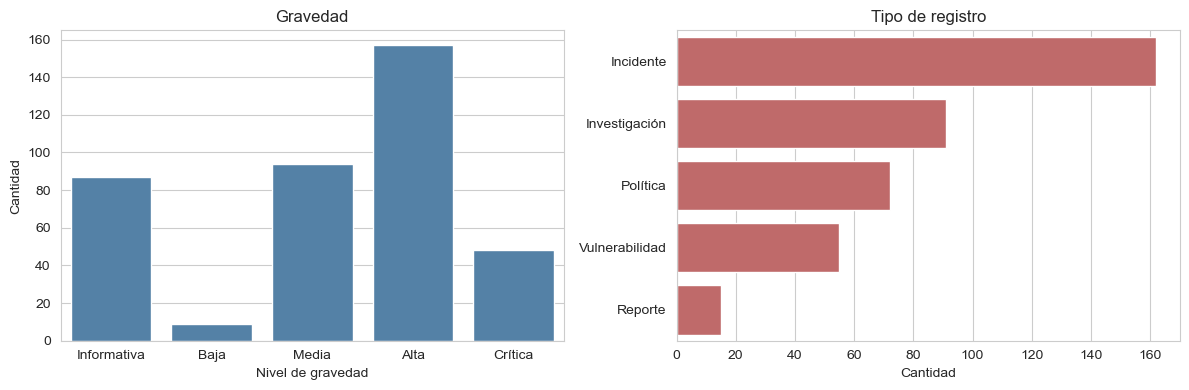

In [18]:
orden = ["Informativa", "Baja", "Media", "Alta", "Crítica"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="gravedad", order=orden, ax=ax[0], color="steelblue")
ax[0].set_title("Gravedad"); ax[0].set_xlabel("Nivel de gravedad"); ax[0].set_ylabel("Cantidad")
sns.countplot(data=df, y="tipo_registro", order=df["tipo_registro"].value_counts().index, ax=ax[1], color="indianred")
ax[1].set_title("Tipo de registro"); ax[1].set_xlabel("Cantidad"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

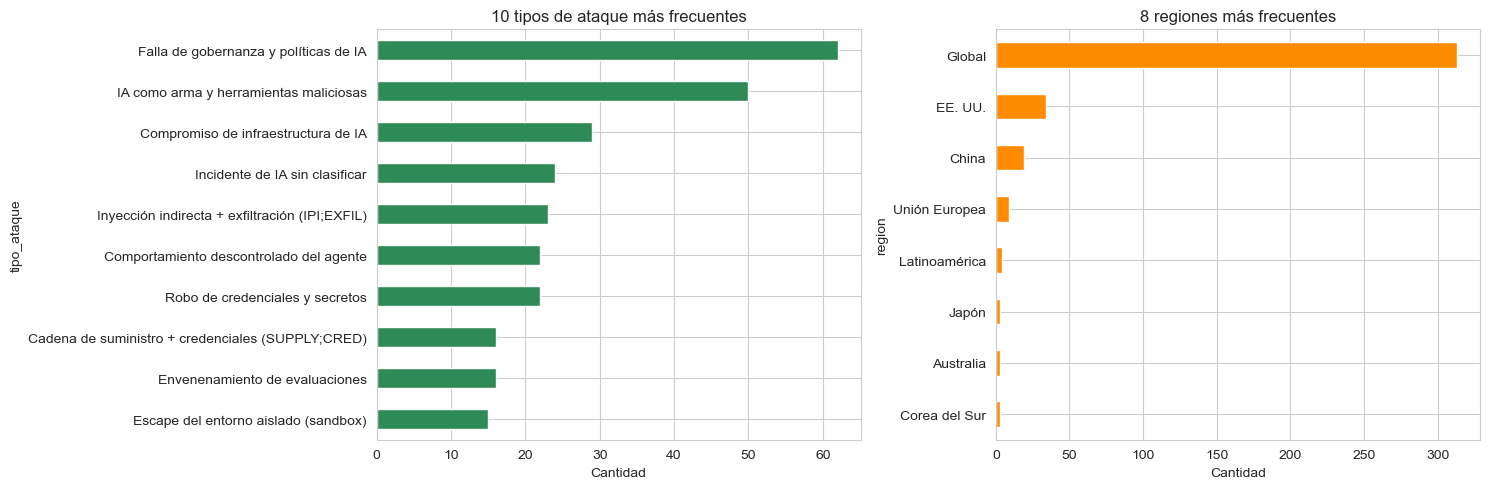

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
df["tipo_ataque"].value_counts().head(10).sort_values().plot.barh(ax=ax[0], color="seagreen")
ax[0].set_title("10 tipos de ataque más frecuentes"); ax[0].set_xlabel("Cantidad")
df["region"].value_counts().head(8).sort_values().plot.barh(ax=ax[1], color="darkorange")
ax[1].set_title("8 regiones más frecuentes"); ax[1].set_xlabel("Cantidad")
plt.tight_layout(); plt.show()

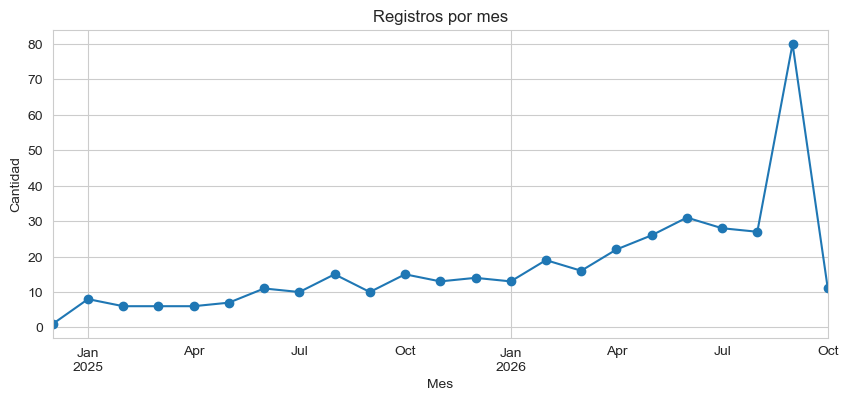

In [20]:
df.groupby(df["fecha"].dt.to_period("M")).size().plot(marker="o", figsize=(10, 4), title="Registros por mes")
plt.xlabel("Mes"); plt.ylabel("Cantidad"); plt.show()

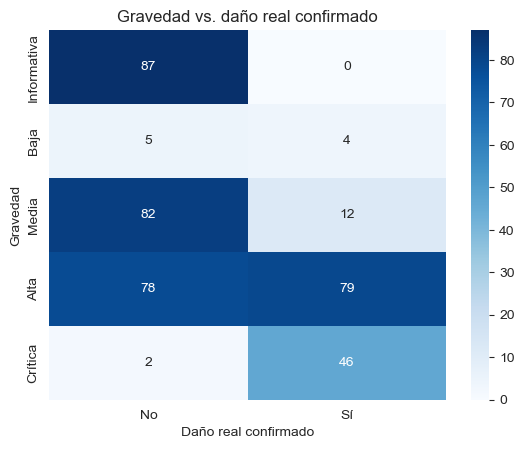

In [21]:
tabla = pd.crosstab(df["gravedad"], df["dano_real"]).reindex(orden)
sns.heatmap(tabla, annot=True, fmt="d", cmap="Blues")
plt.title("Gravedad vs. daño real confirmado"); plt.xlabel("Daño real confirmado"); plt.ylabel("Gravedad"); plt.show()

Preprocesado(disyuntivo)

In [22]:
# 1) Tabla con las 9 variables, agrupando las categorías con pocos casos
top6 = df["tipo_ataque"].value_counts().head(6).index
datos = pd.DataFrame({
    "Gravedad": df["gravedad"],
    "Confianza": np.where(df["confianza"].isin(["A", "B"]), df["confianza"], "C o D"),
    "Tipo de registro": df["tipo_registro"],
    "Participación IA": np.where(df["participacion_ia"] == "Confirmada", "Confirmada", "Otra"),
    "Daño real": df["dano_real"],
    "Evento emblemático": df["evento_emblematico"],
    "Región": np.where(df["region"].isin(["Global", "EE. UU.", "China", "Unión Europea"]), df["region"], "Otra"),
    "Tipo de ataque": np.where(df["tipo_ataque"].isin(top6), df["tipo_ataque"], "Otros"),
    "Año": np.where(df["anio"] >= 2026, "2026", "2025 o antes")})

# 2) Tabla disyuntiva completa: una columna 0/1 por categoría
X = pd.get_dummies(datos, prefix_sep=": ", dtype=int)

# 3) Verificación: cada fila debe sumar 9 (un 1 por variable)
print("Tamaño de la tabla:", X.shape)
print("¿Cada fila suma 9?", (X.sum(axis=1) == datos.shape[1]).all())
X.head()

Tamaño de la tabla: (395, 33)
¿Cada fila suma 9? True


,Gravedad: Alta,Gravedad: Baja,Gravedad: Crítica,Gravedad: Informativa,Gravedad: Media,Confianza: A,Confianza: B,Confianza: C o D,Tipo de registro: Incidente,Tipo de registro: Investigación,...,Región: Unión Europea,Tipo de ataque: Compromiso de infraestructura de IA,Tipo de ataque: Falla de gobernanza y políticas de IA,Tipo de ataque: IA como arma y herramientas maliciosas,Tipo de ataque: Incidente de IA sin clasificar,Tipo de ataque: Inyección indirecta + exfiltración (IPI;EXFIL),Tipo de ataque: Otros,Tipo de ataque: Robo de credenciales y secretos,Año: 2025 o antes,Año: 2026
0,1,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,0,1,1,0
1,0,0,0,0,1,1,0,0,1,0,...,0,0,0,0,1,0,0,0,1,0
2,0,0,0,0,1,1,0,0,1,0,...,0,0,0,0,1,0,0,0,1,0
3,0,0,0,1,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
4,1,0,0,0,0,0,0,1,1,0,...,0,0,0,1,0,0,0,0,1,0


PCA

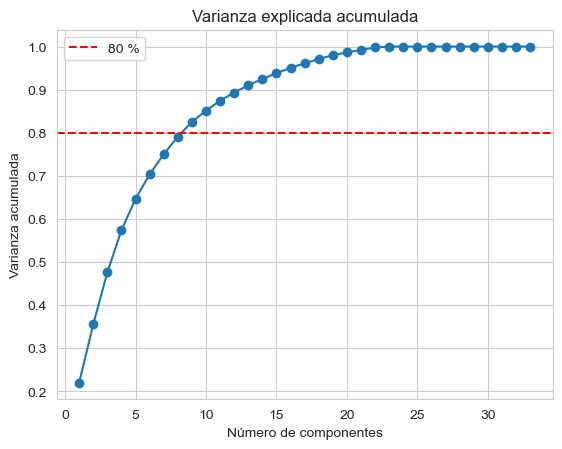

Componentes necesarias para 80 %: 9
Varianza de PC1 y PC2 (%): [22.1 13.5]


In [23]:
pca = PCA().fit(X)
var_acum = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(var_acum) + 1), var_acum, marker="o")
plt.axhline(0.80, color="red", linestyle="--", label="80 %")
plt.xlabel("Número de componentes"); plt.ylabel("Varianza acumulada")
plt.title("Varianza explicada acumulada"); plt.legend(); plt.show()

n_comp = int(np.argmax(var_acum >= 0.80)) + 1
print("Componentes necesarias para 80 %:", n_comp)
print("Varianza de PC1 y PC2 (%):", (pca.explained_variance_ratio_[:2] * 100).round(1))

In [24]:
pca_final = PCA(n_components=n_comp)
Z = pca_final.fit_transform(X)

cargas = pd.DataFrame(pca_final.components_[:2].T, index=X.columns, columns=["PC1", "PC2"]).round(2)
print("Variables con más peso en PC1:")
print(cargas.reindex(cargas["PC1"].abs().sort_values(ascending=False).index).head(6))
print("\nVariables con más peso en PC2:")
print(cargas.reindex(cargas["PC2"].abs().sort_values(ascending=False).index).head(6))

Variables con más peso en PC1:
                              PC1   PC2
Daño real: Sí               -0.44 -0.10
Daño real: No                0.44  0.10
Tipo de registro: Incidente -0.42 -0.06
Gravedad: Informativa        0.28 -0.34
Tipo de registro: Política   0.25 -0.31
Evento emblemático: Sí      -0.24 -0.18

Variables con más peso en PC2:
                             PC1   PC2
Gravedad: Media             0.10  0.35
Año: 2026                  -0.00 -0.34
Gravedad: Informativa       0.28 -0.34
Año: 2025 o antes           0.00  0.34
Tipo de registro: Política  0.25 -0.31
Tipo de ataque: Otros      -0.14  0.29


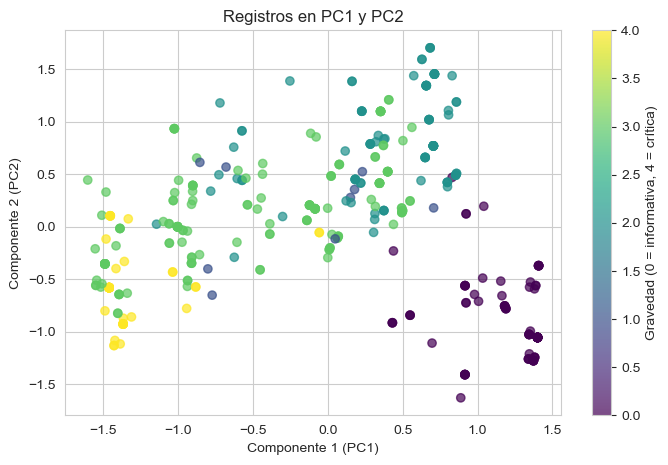

In [25]:
plt.figure(figsize=(8, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=df["gravedad"].map(dict(zip(orden, range(5)))), cmap="viridis", alpha=0.7)
plt.colorbar(label="Gravedad (0 = informativa, 4 = crítica)")
plt.xlabel("Componente 1 (PC1)"); plt.ylabel("Componente 2 (PC2)")
plt.title("Registros en PC1 y PC2"); plt.show()

definir clusters

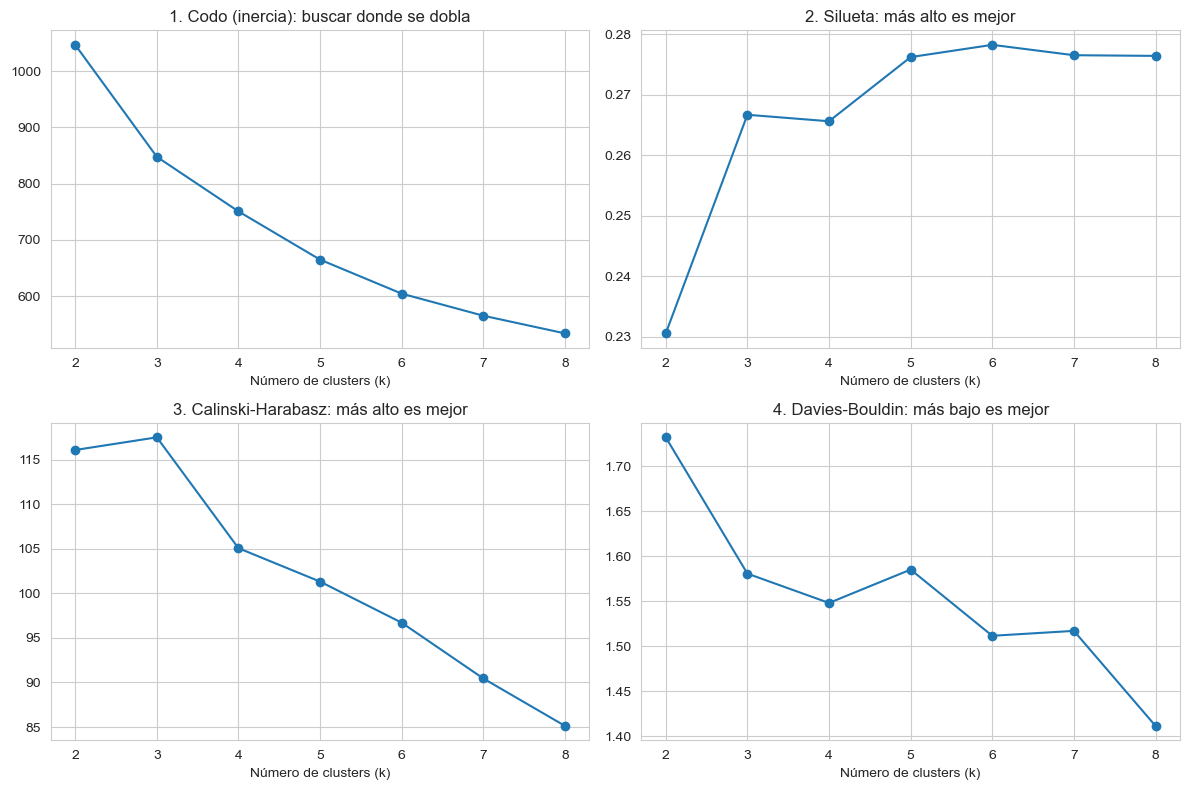

,inercia,silueta,calinski,davies
2,1046.729,0.231,116.094,1.732
3,847.694,0.267,117.514,1.581
4,750.723,0.266,105.072,1.548
5,664.939,0.276,101.321,1.585
6,604.513,0.278,96.707,1.512
7,565.287,0.277,90.448,1.517
8,533.884,0.276,85.127,1.412


In [26]:
ks = range(2, 9)
res = {"inercia": [], "silueta": [], "calinski": [], "davies": []}

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    res["inercia"].append(km.inertia_)
    res["silueta"].append(silhouette_score(Z, km.labels_))
    res["calinski"].append(calinski_harabasz_score(Z, km.labels_))
    res["davies"].append(davies_bouldin_score(Z, km.labels_))

titulos = {"inercia": "1. Codo (inercia): buscar donde se dobla",
           "silueta": "2. Silueta: más alto es mejor",
           "calinski": "3. Calinski-Harabasz: más alto es mejor",
           "davies": "4. Davies-Bouldin: más bajo es mejor"}
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, (nombre, valores) in zip(ax.flatten(), res.items()):
    a.plot(list(ks), valores, marker="o"); a.set_title(titulos[nombre]); a.set_xlabel("Número de clusters (k)")
plt.tight_layout(); plt.show()

pd.DataFrame(res, index=list(ks)).round(3)

K-Medias=4:Los cuatro métodos no coinciden en un único k. Silueta y Calinski-Harabasz muestran que a partir de k = 3 la separación casi no mejora, y Davies-Bouldin es el mejor en k = 4 dentro del rango 2 a 5. Elegí k = 4 porque, además de ser estable en las métricas, permite separar los incidentes con daño real en emblemáticos y no emblemáticos, lo que da una interpretación más útil que k = 3.”

In [27]:
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)
df["cluster"] = km.labels_

perfil = df.groupby("cluster").agg(
    registros=("cluster", "size"),
    tipo_dominante=("tipo_registro", lambda s: s.mode()[0]),
    gravedad_dominante=("gravedad", lambda s: s.mode()[0]),
    pct_dano_real=("dano_real", lambda s: (s == "Sí").mean()),
    pct_emblematico=("evento_emblematico", lambda s: (s == "Sí").mean())).round(2)
perfil

,registros,tipo_dominante,gravedad_dominante,pct_dano_real,pct_emblematico
cluster,,,,,
0,75,Incidente,Alta,0.95,0.01
1,161,Investigación,Media,0.00,0.29
2,86,Política,Informativa,0.00,0.20
3,73,Incidente,Crítica,0.96,1.00


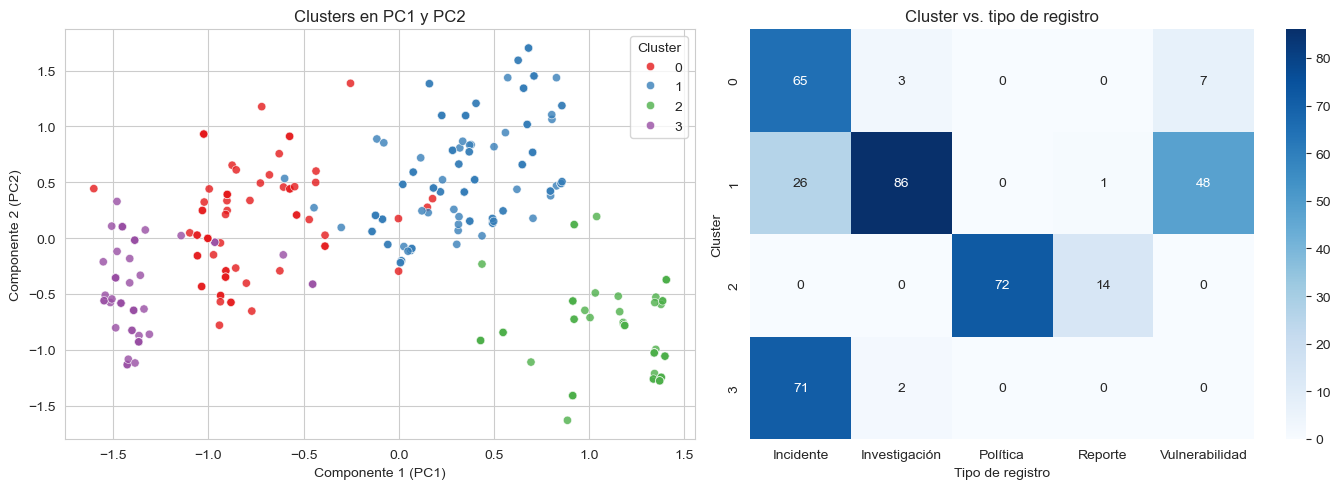

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["cluster"], palette="Set1", alpha=0.8, ax=ax[0])
ax[0].set_title("Clusters en PC1 y PC2"); ax[0].set_xlabel("Componente 1 (PC1)")
ax[0].set_ylabel("Componente 2 (PC2)"); ax[0].legend(title="Cluster")
sns.heatmap(pd.crosstab(df["cluster"], df["tipo_registro"]), annot=True, fmt="d", cmap="Blues", ax=ax[1])
ax[1].set_title("Cluster vs. tipo de registro"); ax[1].set_xlabel("Tipo de registro"); ax[1].set_ylabel("Cluster")
plt.tight_layout(); plt.show()

Interpretación: Grupo	Registros	Perfil
Incidentes emblemáticos	73	Incidentes de gravedad Crítica/Alta, 96 % con daño real y 100 % emblemáticos.
Incidentes comunes	75	Incidentes de gravedad Alta, 95 % con daño real y solo 1 % emblemáticos.
Investigación y vulnerabilidades	161	Gravedad Media, 0 % de daño real.
Políticas y gobernanza	86	Gravedad Informativa, 0 % de daño real.

Variables mas fuertes

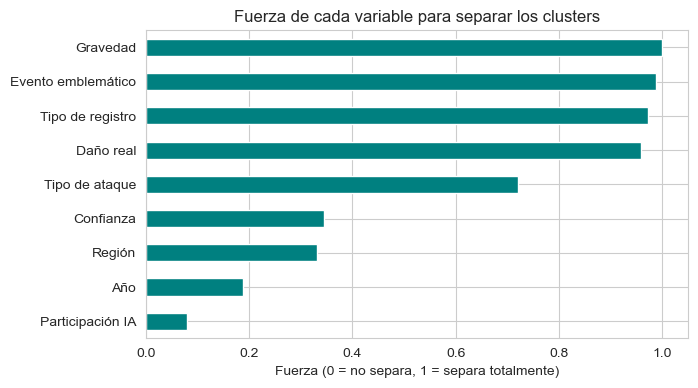

Gravedad              1.00
Evento emblemático    0.99
Tipo de registro      0.97
Daño real             0.96
Tipo de ataque        0.72
Confianza             0.35
Región                0.33
Año                   0.19
Participación IA      0.08
dtype: float64


In [29]:
centros = X.groupby(df["cluster"]).mean()
fuerza = (centros.max() - centros.min()).sort_values(ascending=False)
por_variable = pd.Series({c: fuerza[[x for x in X.columns if x.startswith(c + ": ")]].max()
                          for c in datos.columns}).sort_values()

por_variable.plot.barh(figsize=(7, 4), color="teal")
plt.title("Fuerza de cada variable para separar los clusters")
plt.xlabel("Fuerza (0 = no separa, 1 = separa totalmente)"); plt.show()
print(por_variable.sort_values(ascending=False).round(2))

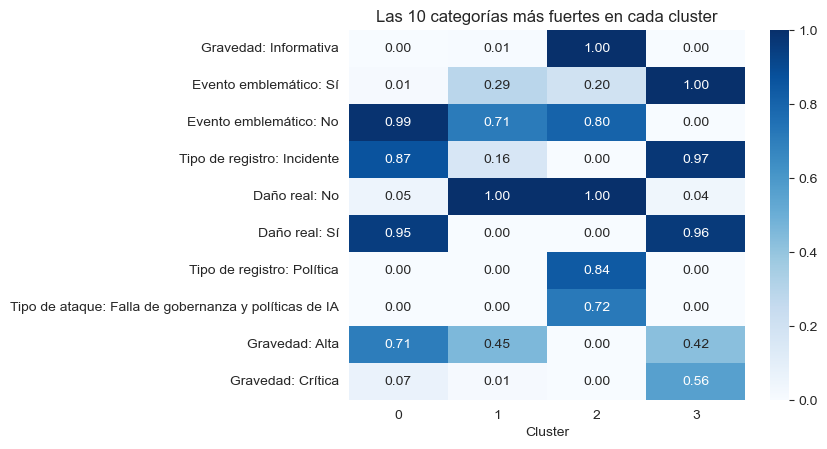

In [30]:
sns.heatmap(centros[fuerza.head(10).index].T, annot=True, fmt=".2f", cmap="Blues")
plt.title("Las 10 categorías más fuertes en cada cluster"); plt.xlabel("Cluster"); plt.show()

Set 2

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency

sns.set_style("whitegrid")

# Busca el CSV junto al notebook y, si no está, en Descargas y todas sus subcarpetas
nombre = "Employee_Performance_Imputed_Distribution.csv"
ruta = Path(nombre)
if not ruta.exists():
    ruta = next(Path.home().joinpath("Downloads").rglob(nombre), None)

if ruta is None:
    raise FileNotFoundError("No encontré el archivo. Revisa el nombre o copia el CSV junto al notebook.")

print("Archivo encontrado en:", ruta)
df = pd.read_csv(ruta)
print("Registros:", df.shape[0], "| Variables:", df.shape[1])
df.head()

Archivo encontrado en: C:\Users\jerie\Downloads\Set_de_datos_Proyecto_Minería_I_Grupo_I\Employee_Performance_Imputed_Distribution.csv
Registros: 1200 | Variables: 40


,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,Avg. sales per day,Avg. sales value,Avg. customer feedback,Salary per Annum lacs,Conversion rate,% of sales from high value products,No. of interactions per customer per customer,Product knowledge score,Customers attended M vs F,Attrition
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,3,40096.77000,3.781753,195769,0.104787,0.229816,1.961721,79.497775,0.415024,No
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,3,16918.86777,2.865392,212194,0.470160,0.448324,1.733028,66.959862,0.411644,No
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,1,232745.48780,3.722888,173590,0.290968,0.146805,1.629473,74.003103,0.415218,No
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,4,351944.31070,4.395204,109538,0.271255,0.286976,4.735974,65.882153,0.352787,No
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,33871.45925,3.161762,105672,0.167018,0.824831,2.649225,66.272329,0.514202,No


In [33]:
df.info()
df.describe(include="all").T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 40 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   EmpNumber                                       1200 non-null   object 
 1   Age                                             1200 non-null   int64  
 2   Gender                                          1200 non-null   object 
 3   EducationBackground                             1200 non-null   object 
 4   MaritalStatus                                   1200 non-null   object 
 5   EmpDepartment                                   1200 non-null   object 
 6   EmpJobRole                                      1200 non-null   object 
 7   BusinessTravelFrequency                         1200 non-null   object 
 8   DistanceFromHome                                1200 non-null   int64  
 9   EmpEducationLevel                        

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
EmpNumber,1200,1200,E1001000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1200.0,NaN,NaN,NaN,36.918333,9.087289,18.0,30.0,36.0,43.0,60.0
Gender,1200,2,Male,725,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EducationBackground,1200,6,Life Sciences,492,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MaritalStatus,1200,3,Married,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmpDepartment,1200,6,Sales,373,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmpJobRole,1200,19,Sales Executive,270,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravelFrequency,1200,3,Travel_Rarely,846,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1200.0,NaN,NaN,NaN,9.165833,8.176636,1.0,2.0,7.0,14.0,29.0
EmpEducationLevel,1200.0,NaN,NaN,NaN,2.8925,1.04412,1.0,2.0,3.0,4.0,5.0


In [34]:
diccionario = pd.DataFrame([
    ("EmpNumber", "Identificador del empleado", "Texto", "Se descarta (identificador)"),
    ("Age", "Edad", "Numérica", "Clusterización (trayectoria)"),
    ("Gender", "Género", "Categórica", "Exploración"),
    ("EducationBackground", "Área de formación", "Categórica", "Exploración"),
    ("MaritalStatus", "Estado civil", "Categórica", "Exploración"),
    ("EmpDepartment", "Departamento", "Categórica", "Exploración e interpretación de grupos"),
    ("EmpJobRole", "Puesto (19 tipos)", "Categórica", "Exploración"),
    ("BusinessTravelFrequency", "Frecuencia de viajes de trabajo", "Categórica", "Exploración"),
    ("DistanceFromHome", "Distancia de la casa al trabajo", "Numérica", "Exploración"),
    ("EmpEducationLevel", "Nivel educativo (1 a 5)", "Ordinal", "Exploración"),
    ("EmpEnvironmentSatisfaction", "Satisfacción con el ambiente (1 a 4)", "Ordinal", "Exploración"),
    ("EmpHourlyRate", "Tarifa por hora", "Numérica", "Exploración"),
    ("EmpJobInvolvement", "Involucramiento en el trabajo (1 a 4)", "Ordinal", "Exploración"),
    ("EmpJobLevel", "Nivel del puesto (1 a 5)", "Ordinal", "Clusterización (trayectoria)"),
    ("EmpJobSatisfaction", "Satisfacción con el trabajo (1 a 4)", "Ordinal", "Exploración"),
    ("NumCompaniesWorked", "Empresas donde ha trabajado", "Numérica", "Exploración"),
    ("OverTime", "Hace horas extra (Sí/No)", "Categórica", "Interpretación de grupos"),
    ("EmpLastSalaryHikePercent", "Último aumento de salario (%)", "Numérica", "Exploración"),
    ("EmpRelationshipSatisfaction", "Satisfacción con las relaciones (1 a 4)", "Ordinal", "Exploración"),
    ("TotalWorkExperienceInYears", "Años de experiencia total", "Numérica", "Clusterización (trayectoria)"),
    ("TrainingTimesLastYear", "Capacitaciones el último año", "Numérica", "Exploración"),
    ("EmpWorkLifeBalance", "Balance vida-trabajo (1 a 4)", "Ordinal", "Exploración"),
    ("ExperienceYearsAtThisCompany", "Años en esta empresa", "Numérica", "Clusterización (trayectoria)"),
    ("ExperienceYearsInCurrentRole", "Años en el puesto actual", "Numérica", "Clusterización (trayectoria)"),
    ("YearsSinceLastPromotion", "Años desde el último ascenso", "Numérica", "Clusterización (trayectoria)"),
    ("YearsWithCurrManager", "Años con el jefe actual", "Numérica", "Clusterización (trayectoria)"),
    ("PerformanceRating", "Calificación de desempeño (2 a 4)", "Ordinal", "Interpretación de grupos (no entra al clustering)"),
    ("Avg no. of engagements per day for last 1 year", "Contactos con clientes por día", "Numérica", "Exploración"),
    ("Avg no. of demos per day for last 1 year", "Demostraciones por día", "Numérica", "Exploración"),
    ("Avg. interaction time per customer seconds", "Tiempo de interacción por cliente (seg)", "Numérica", "Exploración"),
    ("Avg. sales per day", "Ventas promedio por día", "Numérica", "Exploración"),
    ("Avg. sales value", "Valor promedio de las ventas", "Numérica", "Exploración"),
    ("Avg. customer feedback", "Calificación promedio de los clientes", "Numérica", "Exploración"),
    ("Salary per Annum lacs", "Salario anual", "Numérica", "Exploración (sin relación con las demás)"),
    ("Conversion rate", "Tasa de conversión de ventas", "Numérica", "Exploración"),
    ("% of sales from high value products", "% de ventas de productos de alto valor", "Numérica", "Exploración"),
    ("No. of interactions per customer per customer", "Interacciones por cliente", "Numérica", "Exploración"),
    ("Product knowledge score", "Puntaje de conocimiento del producto", "Numérica", "Exploración"),
    ("Customers attended M vs F", "Proporción de clientes atendidos hombres vs mujeres", "Numérica", "Exploración"),
    ("Attrition", "Renuncia (Sí/No)", "Categórica", "Interpretación de grupos (no entra al clustering)"),
], columns=["Variable (CSV)", "Descripción en español", "Tipo", "Uso en el análisis"])
diccionario

,Variable (CSV),Descripción en español,Tipo,Uso en el análisis
0,EmpNumber,Identificador del empleado,Texto,Se descarta (identificador)
1,Age,Edad,Numérica,Clusterización (trayectoria)
2,Gender,Género,Categórica,Exploración
3,EducationBackground,Área de formación,Categórica,Exploración
4,MaritalStatus,Estado civil,Categórica,Exploración
5,EmpDepartment,Departamento,Categórica,Exploración e interpretación de grupos
6,EmpJobRole,Puesto (19 tipos),Categórica,Exploración
7,BusinessTravelFrequency,Frecuencia de viajes de trabajo,Categórica,Exploración
8,DistanceFromHome,Distancia de la casa al trabajo,Numérica,Exploración
9,EmpEducationLevel,Nivel educativo (1 a 5),Ordinal,Exploración


Objetivo:Objetivo: descubrir qué perfiles de empleados existen según su trayectoria en la empresa
(edad, experiencia, antigüedad, ascensos y nivel del puesto), y ver si esos perfiles se
relacionan con el desempeño y con las renuncias.

Preguntas:
1. ¿Cómo se distribuyen el desempeño, las renuncias, los departamentos y la edad?
2. ¿Qué variables de trayectoria se relacionan entre sí?
3. ¿Existen grupos naturales de empleados?
4. ¿Los grupos se diferencian en desempeño y en renuncias?

In [36]:
 print("Nulos:", df.isnull().sum().sum(), "| Duplicados:", df.duplicated().sum(),
      "| IDs repetidos:", df["EmpNumber"].duplicated().sum())

Nulos: 0 | Duplicados: 0 | IDs repetidos: 0


In [37]:
# Nombres de columnas en español
df = df.rename(columns={
    "EmpNumber": "id_empleado", "Age": "edad", "Gender": "genero", "EducationBackground": "formacion",
    "MaritalStatus": "estado_civil", "EmpDepartment": "departamento", "EmpJobRole": "puesto",
    "BusinessTravelFrequency": "viajes", "DistanceFromHome": "distancia_casa", "EmpEducationLevel": "nivel_educativo",
    "EmpEnvironmentSatisfaction": "sat_ambiente", "EmpHourlyRate": "tarifa_hora", "EmpJobInvolvement": "involucramiento",
    "EmpJobLevel": "nivel_puesto", "EmpJobSatisfaction": "sat_trabajo", "NumCompaniesWorked": "num_empresas",
    "OverTime": "horas_extra", "EmpLastSalaryHikePercent": "aumento_salario_pct", "EmpRelationshipSatisfaction": "sat_relaciones",
    "TotalWorkExperienceInYears": "exp_total", "TrainingTimesLastYear": "capacitaciones", "EmpWorkLifeBalance": "balance_vida",
    "ExperienceYearsAtThisCompany": "anios_empresa", "ExperienceYearsInCurrentRole": "anios_puesto",
    "YearsSinceLastPromotion": "anios_sin_ascenso", "YearsWithCurrManager": "anios_con_jefe", "PerformanceRating": "desempeno",
    "Avg no. of engagements per day for last 1 year": "contactos_dia", "Avg no. of demos per day for last 1 year": "demos_dia",
    "Avg. interaction time per customer seconds": "tiempo_interaccion", "Avg. sales per day": "ventas_dia",
    "Avg. sales value": "valor_venta", "Avg. customer feedback": "calif_clientes", "Salary per Annum lacs": "salario_anual",
    "Conversion rate": "tasa_conversion", "% of sales from high value products": "pct_alto_valor",
    "No. of interactions per customer per customer": "interacciones_cliente", "Product knowledge score": "conocimiento_producto",
    "Customers attended M vs F": "clientes_m_vs_f", "Attrition": "renuncia"})

# Valores en español (solo las variables que usaremos en gráficos y tablas)
df["genero"] = df["genero"].map({"Male": "Masculino", "Female": "Femenino"})
df["horas_extra"] = df["horas_extra"].map({"Yes": "Sí", "No": "No"})
df["renuncia"] = df["renuncia"].map({"Yes": "Sí", "No": "No"})
df["departamento"] = df["departamento"].map({"Sales": "Ventas", "Development": "Desarrollo",
    "Research & Development": "Investigación y Desarrollo", "Human Resources": "Recursos Humanos",
    "Finance": "Finanzas", "Data Science": "Ciencia de Datos"})

# Quitar el identificador (no sirve para agrupar)
df = df.drop(columns=["id_empleado"])
df.head()

,edad,genero,formacion,estado_civil,departamento,puesto,viajes,distancia_casa,nivel_educativo,sat_ambiente,...,ventas_dia,valor_venta,calif_clientes,salario_anual,tasa_conversion,pct_alto_valor,interacciones_cliente,conocimiento_producto,clientes_m_vs_f,renuncia
0,32,Masculino,Marketing,Single,Ventas,Sales Executive,Travel_Rarely,10,3,4,...,3,40096.77000,3.781753,195769,0.104787,0.229816,1.961721,79.497775,0.415024,No
1,47,Masculino,Marketing,Single,Ventas,Sales Executive,Travel_Rarely,14,4,4,...,3,16918.86777,2.865392,212194,0.470160,0.448324,1.733028,66.959862,0.411644,No
2,40,Masculino,Life Sciences,Married,Ventas,Sales Executive,Travel_Frequently,5,4,4,...,1,232745.48780,3.722888,173590,0.290968,0.146805,1.629473,74.003103,0.415218,No
3,41,Masculino,Human Resources,Divorced,Recursos Humanos,Manager,Travel_Rarely,10,4,2,...,4,351944.31070,4.395204,109538,0.271255,0.286976,4.735974,65.882153,0.352787,No
4,60,Masculino,Marketing,Single,Ventas,Sales Executive,Travel_Rarely,16,4,1,...,4,33871.45925,3.161762,105672,0.167018,0.824831,2.649225,66.272329,0.514202,No


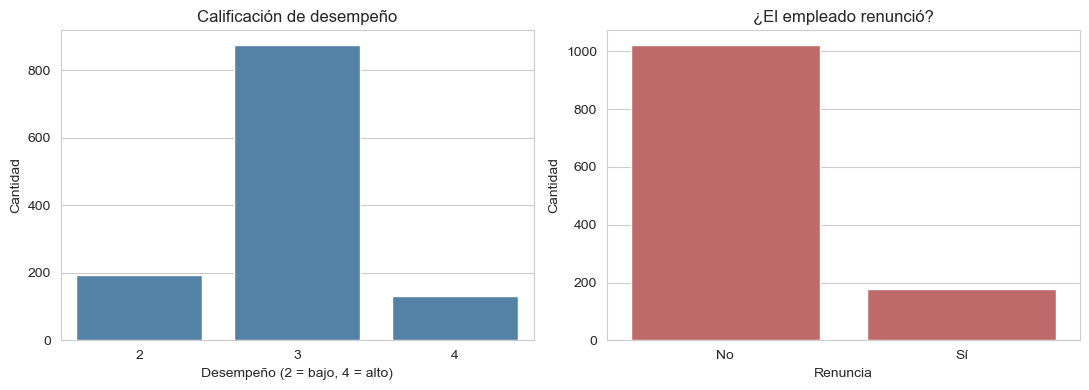

In [38]:
##Eda 
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="desempeno", ax=ax[0], color="steelblue")
ax[0].set_title("Calificación de desempeño"); ax[0].set_xlabel("Desempeño (2 = bajo, 4 = alto)"); ax[0].set_ylabel("Cantidad")
sns.countplot(data=df, x="renuncia", ax=ax[1], color="indianred")
ax[1].set_title("¿El empleado renunció?"); ax[1].set_xlabel("Renuncia"); ax[1].set_ylabel("Cantidad")
plt.tight_layout(); plt.show()

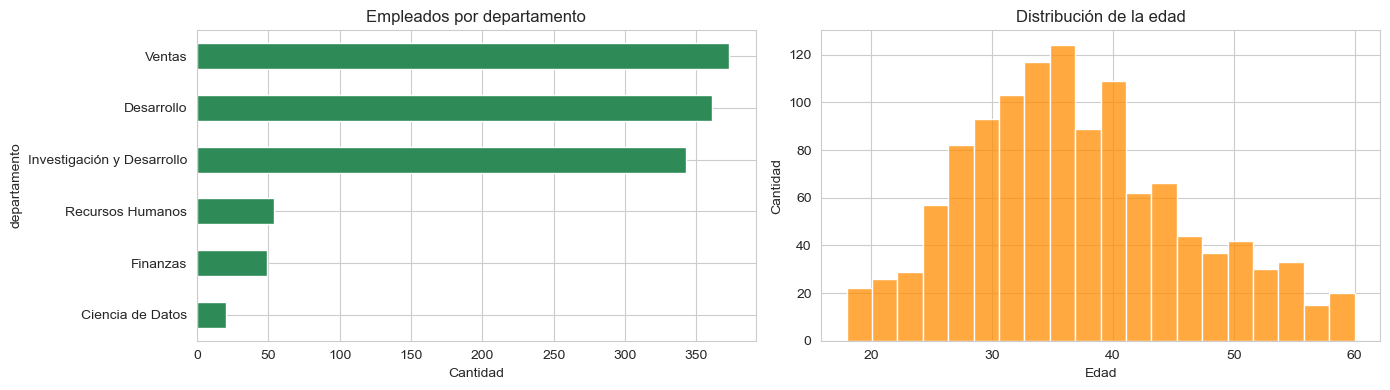

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df["departamento"].value_counts().sort_values().plot.barh(ax=ax[0], color="seagreen")
ax[0].set_title("Empleados por departamento"); ax[0].set_xlabel("Cantidad")
sns.histplot(df["edad"], bins=20, ax=ax[1], color="darkorange")
ax[1].set_title("Distribución de la edad"); ax[1].set_xlabel("Edad"); ax[1].set_ylabel("Cantidad")
plt.tight_layout(); plt.show()

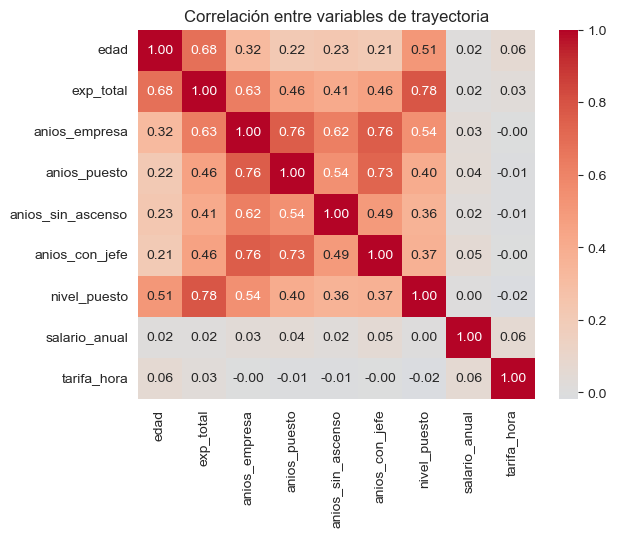

In [40]:
variables = ["edad", "exp_total", "anios_empresa", "anios_puesto", "anios_sin_ascenso", "anios_con_jefe", "nivel_puesto"]

sns.heatmap(df[variables + ["salario_anual", "tarifa_hora"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables de trayectoria"); plt.show()

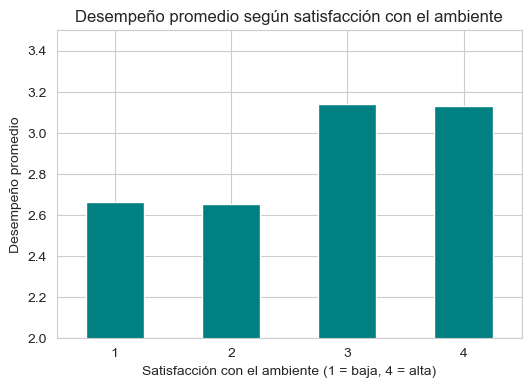

In [41]:
df.groupby("sat_ambiente")["desempeno"].mean().plot.bar(color="teal", figsize=(6, 4), rot=0)
plt.title("Desempeño promedio según satisfacción con el ambiente")
plt.xlabel("Satisfacción con el ambiente (1 = baja, 4 = alta)"); plt.ylabel("Desempeño promedio"); plt.ylim(2, 3.5); plt.show()

preprocesado

In [42]:
# 1) Elegir las variables de trayectoria y estandarizarlas
X = df[variables]
X_esc = StandardScaler().fit_transform(X)

# 2) Justificar la elección: comparar contra usar todas las variables numéricas
todas = df.select_dtypes("number").drop(columns=["desempeno"]).columns
for nombre, cols in {"Todas las numéricas (%d)" % len(todas): list(todas), "Trayectoria (7)": variables}.items():
    Xc = StandardScaler().fit_transform(df[cols])
    etiquetas = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Xc)
    print(nombre, "-> silueta:", round(silhouette_score(Xc, etiquetas), 3))

Todas las numéricas (30) -> silueta: 0.053
Trayectoria (7) -> silueta: 0.334


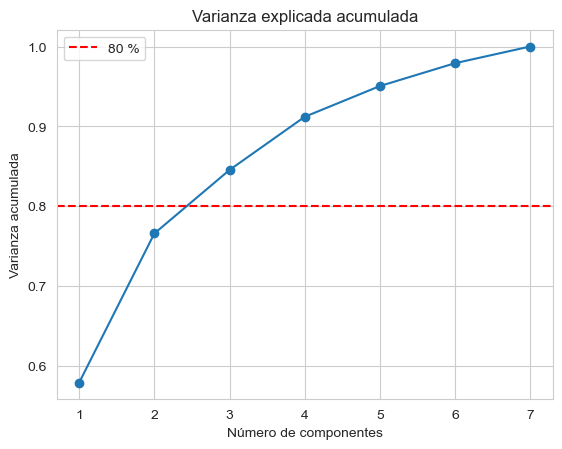

Componentes para 80 %: 3 | PC1 y PC2 (%): [57.9 18.7]


In [43]:
##PCA
pca = PCA().fit(X_esc)
var_acum = np.cumsum(pca.explained_variance_ratio_)

plt.plot(range(1, len(var_acum) + 1), var_acum, marker="o")
plt.axhline(0.80, color="red", linestyle="--", label="80 %")
plt.xlabel("Número de componentes"); plt.ylabel("Varianza acumulada")
plt.title("Varianza explicada acumulada"); plt.legend(); plt.show()

n_comp = int(np.argmax(var_acum >= 0.80)) + 1
print("Componentes para 80 %:", n_comp, "| PC1 y PC2 (%):", (pca.explained_variance_ratio_[:2] * 100).round(1))

In [44]:
pca_final = PCA(n_components=n_comp)
Z = pca_final.fit_transform(X_esc)

cargas = pd.DataFrame(pca_final.components_[:2].T, index=variables, columns=["PC1", "PC2"]).round(2)
cargas

,PC1,PC2
edad,0.28,0.58
exp_total,0.41,0.39
anios_empresa,0.44,-0.22
anios_puesto,0.39,-0.36
anios_sin_ascenso,0.34,-0.25
anios_con_jefe,0.38,-0.36
nivel_puesto,0.37,0.38


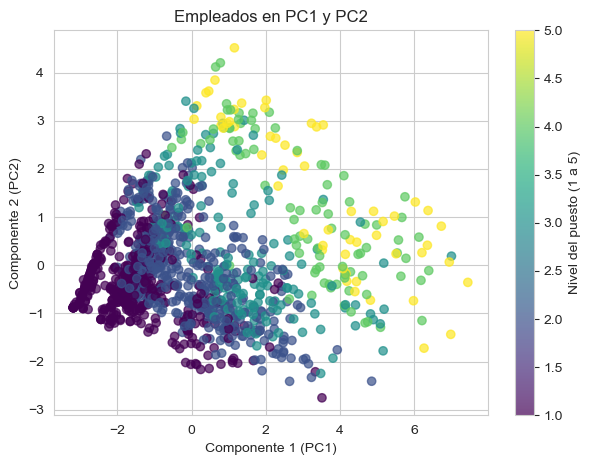

In [45]:
plt.figure(figsize=(7, 5))
plt.scatter(Z[:, 0], Z[:, 1], c=df["nivel_puesto"], cmap="viridis", alpha=0.7)
plt.colorbar(label="Nivel del puesto (1 a 5)")
plt.xlabel("Componente 1 (PC1)"); plt.ylabel("Componente 2 (PC2)"); plt.title("Empleados en PC1 y PC2"); plt.show()

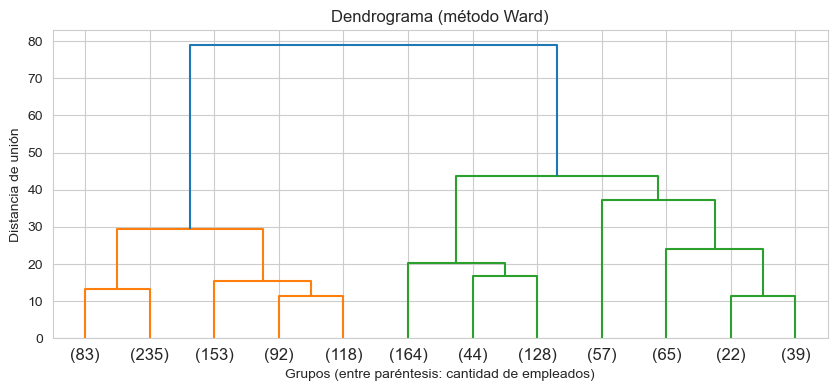

In [46]:
##Elegir el número de clusters (jerárquico Ward)
enlace = linkage(Z, method="ward")

plt.figure(figsize=(10, 4))
dendrogram(enlace, truncate_mode="lastp", p=12, show_leaf_counts=True)
plt.title("Dendrograma (método Ward)")
plt.xlabel("Grupos (entre paréntesis: cantidad de empleados)"); plt.ylabel("Distancia de unión")
plt.show()

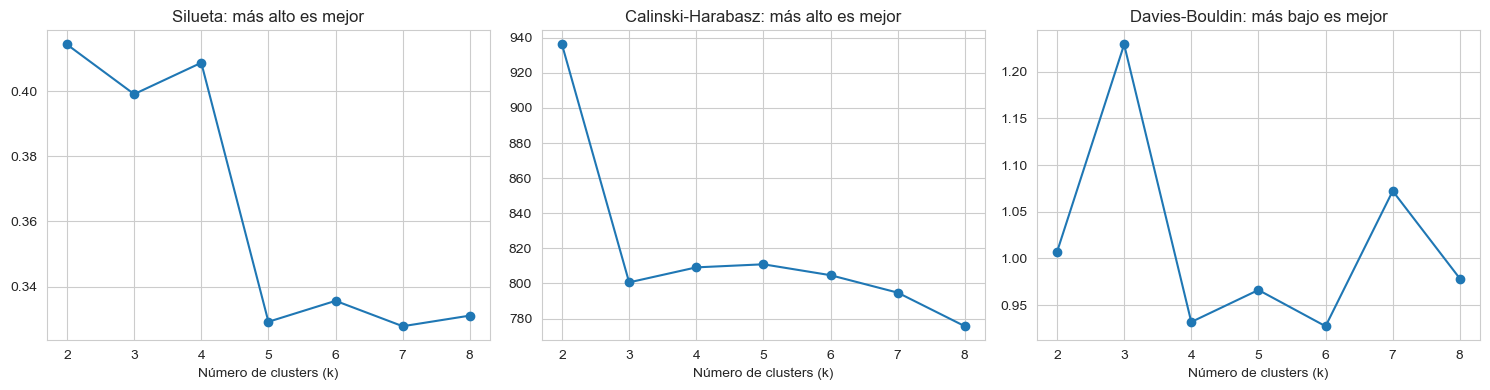

,silueta,calinski,davies
2,0.414,936.131,1.007
3,0.399,800.609,1.229
4,0.409,809.153,0.932
5,0.329,810.906,0.966
6,0.336,804.688,0.927
7,0.328,794.757,1.072
8,0.331,775.619,0.978


In [47]:
ks = range(2, 9)
res = {"silueta": [], "calinski": [], "davies": []}

for k in ks:
    etiquetas = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
    res["silueta"].append(silhouette_score(Z, etiquetas))
    res["calinski"].append(calinski_harabasz_score(Z, etiquetas))
    res["davies"].append(davies_bouldin_score(Z, etiquetas))

titulos = {"silueta": "Silueta: más alto es mejor",
           "calinski": "Calinski-Harabasz: más alto es mejor",
           "davies": "Davies-Bouldin: más bajo es mejor"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (nombre, valores) in zip(ax, res.items()):
    a.plot(list(ks), valores, marker="o"); a.set_title(titulos[nombre]); a.set_xlabel("Número de clusters (k)")
plt.tight_layout(); plt.show()

pd.DataFrame(res, index=list(ks)).round(3)

In [48]:
##4
ward = AgglomerativeClustering(n_clusters=4, linkage="ward")
df["cluster"] = ward.fit_predict(Z)

perfil = df.groupby("cluster").agg(
    registros=("cluster", "size"),
    edad=("edad", "mean"),
    exp_total=("exp_total", "mean"),
    anios_empresa=("anios_empresa", "mean"),
    anios_sin_ascenso=("anios_sin_ascenso", "mean"),
    nivel_puesto=("nivel_puesto", "mean"),
    desempeno=("desempeno", "mean"),
    pct_renuncia=("renuncia", lambda s: (s == "Sí").mean())).round(2)
perfil

,registros,edad,exp_total,anios_empresa,anios_sin_ascenso,nivel_puesto,desempeno,pct_renuncia
cluster,,,,,,,,
0,681,34.23,7.16,3.45,0.68,1.52,3.00,0.20
1,126,46.53,25.43,19.77,7.42,3.93,2.85,0.08
2,336,36.36,12.05,10.19,3.52,2.12,2.87,0.10
3,57,51.09,25.67,4.00,0.91,4.14,3.00,0.02


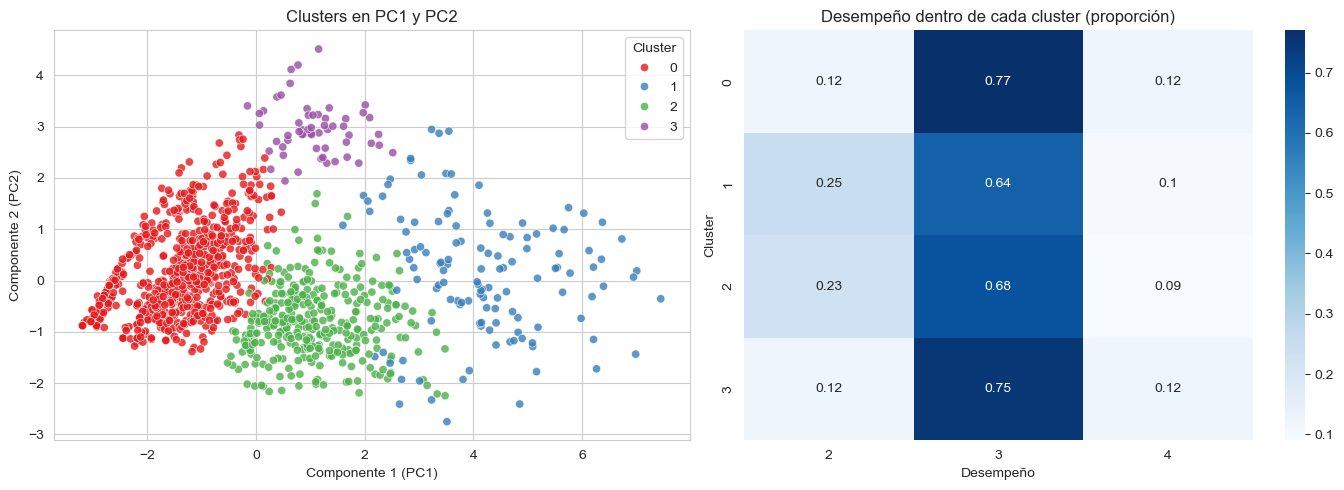

In [49]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df["cluster"], palette="Set1", alpha=0.8, ax=ax[0])
ax[0].set_title("Clusters en PC1 y PC2"); ax[0].set_xlabel("Componente 1 (PC1)"); ax[0].set_ylabel("Componente 2 (PC2)")
ax[0].legend(title="Cluster")
sns.heatmap(pd.crosstab(df["cluster"], df["desempeno"], normalize="index").round(2), annot=True, cmap="Blues", ax=ax[1])
ax[1].set_title("Desempeño dentro de cada cluster (proporción)"); ax[1].set_xlabel("Desempeño"); ax[1].set_ylabel("Cluster")
plt.tight_layout(); plt.show()

In [50]:
print("p desempeño:", chi2_contingency(pd.crosstab(df["cluster"], df["desempeno"]))[1])
print("p renuncia:", chi2_contingency(pd.crosstab(df["cluster"], df["renuncia"]))[1])
pd.crosstab(df["cluster"], df["renuncia"], normalize="index").round(2)

p desempeño: 4.309742986700808e-05
p renuncia: 1.2138931180610568e-06


renuncia,No,Sí
cluster,,
0,0.80,0.20
1,0.92,0.08
2,0.90,0.10
3,0.98,0.02


In [51]:
##Comparar con k.medias
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Z)

print("Coincidencia entre Ward y K-medias (ARI):", round(adjusted_rand_score(df["cluster"], km.labels_), 2))
print("Silueta Ward:", round(silhouette_score(Z, df["cluster"]), 3), "| Silueta K-medias:", round(silhouette_score(Z, km.labels_), 3))
pd.crosstab(df["cluster"], km.labels_, rownames=["Ward"], colnames=["K-medias"])

Coincidencia entre Ward y K-medias (ARI): 0.78
Silueta Ward: 0.409 | Silueta K-medias: 0.426


K-medias,0,1,2,3
Ward,,,,
0,593,0,15,73
1,0,108,7,11
2,1,8,320,7
3,0,0,0,57


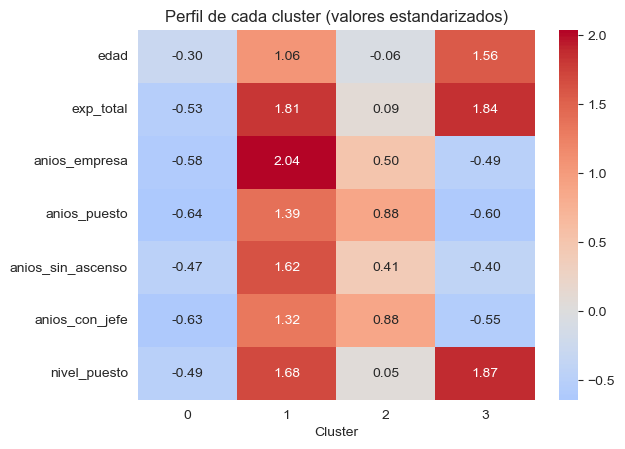

anios_empresa        2.62
exp_total            2.37
nivel_puesto         2.36
anios_sin_ascenso    2.09
anios_puesto         2.03
anios_con_jefe       1.95
edad                 1.86
dtype: float64

In [52]:
##Variables mas fuertes
medias = pd.DataFrame(X_esc, columns=variables).groupby(df["cluster"].values).mean()

sns.heatmap(medias.T, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Perfil de cada cluster (valores estandarizados)"); plt.xlabel("Cluster"); plt.show()

fuerza = (medias.max() - medias.min()).sort_values(ascending=False).round(2)
fuerza

Conclusiones: - El dataset tiene 1200 empleados y 40 variables, sin nulos. Se agrupó por trayectoria (7 variables).
- Con todas las variables numéricas casi no hay grupos (silueta 0.05); con las de trayectoria
  la silueta sube a 0.33-0.41. Salario y tarifa por hora no se relacionan con nada y se dejaron fuera.
- El PCA resume la trayectoria en 3 componentes (85 % de la información).
- Con clustering jerárquico Ward (k = 4) se encontraron 4 perfiles: inicio de carrera, experiencia media
  en la empresa, veteranos y perfiles senior de ingreso reciente. K-medias da casi lo mismo (ARI = 0.78).
- Los grupos se relacionan con las renuncias (20 % en inicio de carrera, 2 % en perfiles senior de ingreso
  reciente) y con el desempeño (más calificaciones bajas en los grupos con más años sin ascenso).
- Limitaciones: los grupos separan sobre todo por antigüedad, algo esperable; las relaciones con renuncia
  y desempeño son asociaciones, no causas; y la elección de k no es única (k = 2 también es válido).

In [53]:
##Forest
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# Lo que queremos predecir (y) y las variables que usamos para predecir (X)
y = df["desempeno"]
X_pred = pd.get_dummies(df.drop(columns=["desempeno", "renuncia", "cluster"]), dtype=int)

# Separar 80 % para entrenar y 20 % para probar
X_train, X_test, y_train, y_test = train_test_split(X_pred, y, test_size=0.2, random_state=42, stratify=y)

# Entrenar el modelo y predecir
modelo = RandomForestClassifier(n_estimators=200, random_state=42)
modelo.fit(X_train, y_train)
pred = modelo.predict(X_test)

print("Exactitud del modelo:", round(accuracy_score(y_test, pred), 3))
print("Exactitud de adivinar siempre la clase más común:", round((y_test == y_train.mode()[0]).mean(), 3))
print(classification_report(y_test, pred))

Exactitud del modelo: 0.896
Exactitud de adivinar siempre la clase más común: 0.729
              precision    recall  f1-score   support

           2       0.89      0.64      0.75        39
           3       0.89      0.98      0.93       175
           4       1.00      0.69      0.82        26

    accuracy                           0.90       240
   macro avg       0.93      0.77      0.83       240
weighted avg       0.90      0.90      0.89       240



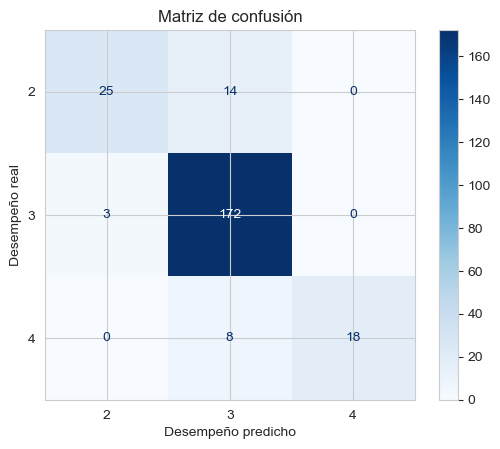

In [83]:
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.title("Matriz de confusión"); plt.xlabel("Desempeño predicho"); plt.ylabel("Desempeño real"); plt.show()

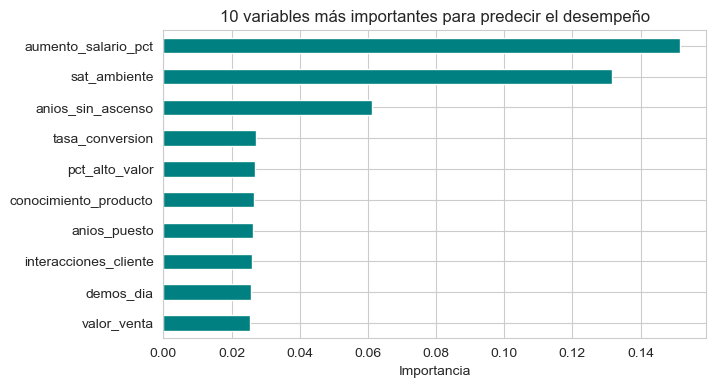

aumento_salario_pct      0.152
sat_ambiente             0.132
anios_sin_ascenso        0.061
tasa_conversion          0.027
pct_alto_valor           0.027
conocimiento_producto    0.027
anios_puesto             0.026
interacciones_cliente    0.026
demos_dia                0.026
valor_venta              0.025
dtype: float64

In [84]:
importancia = pd.Series(modelo.feature_importances_, index=X_pred.columns).sort_values().tail(10)
importancia.plot.barh(color="teal", figsize=(7, 4))
plt.title("10 variables más importantes para predecir el desempeño"); plt.xlabel("Importancia"); plt.show()
importancia.sort_values(ascending=False).round(3)